In [4]:
import math
import numpy as np
import matplotlib.pyplot as plt

# 1.导数和变化量

In [4]:
def f(x):
    return 3*x**2 -4*x + 5

In [5]:
f(3.0)

20.0

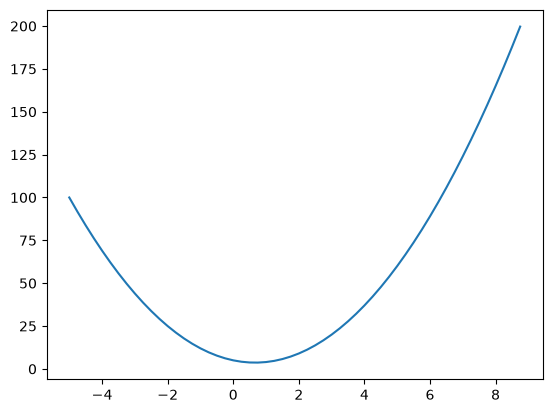

In [6]:
xs = np.arange(-5,9,0.25)
ys = f(xs)
plt.plot(xs,ys)

In [10]:
h = 0.0000000001
x = 3.0
print(f(x))
print(f(x+h))
d = f(x+h) - f(x)
s = d / h
print(d)
print(s)

20.0
20.0000000014
1.4000001158365194e-09
14.000001158365194


In [12]:
h = 0.000001
x = 2/3
print(f(x))
print(f(x+h))
s = (f(x+h)-f(x)) / h
print(s)
# x对应的导数接近于 0，此时正向移动 x，对应的导数几乎不变

3.666666666666667
3.6666666666696663
2.999378523327323e-06


In [13]:
a = 2.0
b = -3.0
c = 10.0
d = a*b +c
print(d)

4.0


In [14]:
h = 0.00001

a = 2.0
b = -3.0
c = 10.0
d = a*b +c
print(d)

# 想知道d相较于a的导数
d1 = a*b +c
a += h
d2 = a*b +c

print("d1 =",d1)
print("d2 =",d2)
print("slope=",(d2-d1)/h)

4.0
d1 = 4.0
d2 = 3.9999699999999994
slope= -3.000000000064062


# 2.构建micrograd

In [20]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data = data
        # grad记录Value对象对函数Loss的贡献
        self.grad = 0.0
        self._prev=set(_children)
        self._op=_op
        self.label=label
        # prev记录进行处理的对象,_op记录执行的运算，label记录变量名
    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data,(self,other),'+')
        return out
    def __mul__(self, other):
        out = Value(self.data * other.data,(self,other),'*')
        return out
    def __sub__(self, other):
        out = Value(self.data - other.data,(self,other),'-')
        return out

In [11]:
a = Value(2.0,label='a')
b = Value(3.0,label='b')
c = Value(4.0,label='c')
a
b = Value(-3.0)
b
c = Value(10.0)
c

Value(data=10.0)

In [25]:
a+b

Value(data=-1.0)

In [26]:
a*b

Value(data=-6.0)

In [27]:
a-b

Value(data=5.0)

In [15]:
e = a*b;e.label='e'
d = e+c
# (a.__mul__(b)).__add__(c)

In [16]:
# 查看 d 的来源
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [17]:
d._op

'+'

In [1]:
# 可视化运算经过与变量
from graphviz import Digraph

In [21]:
def trace(root):
    # 构建运算变量（节点）和运算操作（边）的图
    nodes,edges = set(),set()
    def build(v):
        nodes.add(v)
        for child in v._prev:
            edges.add((child,v))
            build(child)
    build(root)
    return nodes,edges

def draw_dot(root):
    dot = Digraph(format='svg',graph_attr={'rankdir':'LR'})

    nodes,edges = trace(root)
    for n in nodes:
        uid =str(id(n))
        dot.node(uid,label=f"label {n.label} data {n.data:.4f} grad {n.grad:.4f}", shape="record")
        if n._op:
            dot.node(name= uid + n._op,label=n._op)
            dot.edge(uid+n._op,uid)

        for n1,n2 in edges:
            dot.edge(str(id(n1)), str(id(n2))+n2._op)
    return dot


In [9]:
draw_dot(d)

ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

In [19]:
f = Value(2.0,label='f')
L = d*f
L

Value(data=8.0)